# Chapter 20: Deploying to production

This notebook runs every experiment in the chapter, top to bottom, on one machine:

1. **Images**: Chapter 1's chat API in a naive Dockerfile vs a multi-stage one.
2. **Compose prod profile**: both services (chat + the Chapter 6 data bot) with the eval gate in front of them.
3. **kind**: a 3-node local Kubernetes cluster. The naive manifest (v0), what breaks, then the hardened one:
   sessions in Postgres, probes, graceful shutdown, HPA, PodDisruptionBudget.
4. **Prompt canary**: v2 of the system prompt to 10% then 50% of sessions, analysed from the pods' logs.
5. **GPU serving manifests** (vLLM production-stack, KServe), rendered and validated, not run.

Prerequisites: Docker, `kind`, `kubectl` and `helm` on the `PATH` (see the chapter README for the Linux
install), the ShopFlow database (`docker compose -f datasets/shopflow/docker-compose.yml up -d`) and `.env`.
Load tests use an in-cluster fake LLM, so they cost nothing; only the gate and the canary call
`openai/gpt-6-luna`. Expect about 25 minutes and a few cents.

In [1]:
import asyncio
import json
import os
import shutil
import statistics
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd
import yaml

HERE = Path.cwd()
for path in (HERE, HERE / "services" / "chat", HERE / "services" / "sqlbot"):
    sys.path.insert(0, str(path))
import ch20_canary as canary
import ch20_eval_gate as gate
import ch20_loadgen as lg
import ch20_ops as ops
from ch20_chat.core import count_tokens
from ch20_sqlbot import agent as sqlbot_agent
from llmprod import get_settings

REPO = HERE.parents[1]
IMAGES = REPO / "ch20" / "images"
RESULTS = HERE / "eval" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
SVC = HERE / "services"
settings = get_settings()
pd.set_option("display.width", 140)

for cmd in ["docker version --format 'docker {{.Server.Version}}'", "docker compose version",
            "kind version", "kubectl version --client | head -1", "helm version --short"]:
    print(ops.sh(cmd))


def openrouter_usage() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key",
                  headers={"Authorization": f"Bearer {settings.llm_api_key}"}, timeout=20)
    return r.json()["data"]["usage"]


USAGE_BEFORE = openrouter_usage()
SPEND: dict[str, float] = {}   # our own hosted-model spend, from each response's usage.cost
print(f"OpenRouter key usage before this notebook: ${USAGE_BEFORE:.4f} (shared key)")

docker 29.1.3
Docker Compose version v5.7.0
kind v0.33.0 go1.26.7 linux/amd64
Client Version: v1.37.2
v4.3.1+gc0d08d0
OpenRouter key usage before this notebook: $154.2542 (shared key)


## 1. Images: naive vs multi-stage

We build the production images from the committed sources, then measure the naive Dockerfile
(`services/chat/Dockerfile.naive`) against the multi-stage one (`services/chat/Dockerfile`) in a
scratch copy of the chat service: image size, layers, user, and the rebuild time after a
one-line code change.

In [2]:
def build(tag: str, context: Path, dockerfile: str = "Dockerfile") -> float:
    t0 = time.perf_counter()
    ops.sh(f"docker build -q -f {context / dockerfile} -t {tag} {context}", timeout=3600)
    return round(time.perf_counter() - t0, 1)


def facts(tag: str) -> dict:
    info = json.loads(ops.sh(f"docker image inspect {tag}"))[0]
    return {"size_MB": round(info["Size"] / 1e6), "layers": len(info["RootFS"]["Layers"]),
            "user": info["Config"].get("User") or "root"}


for svc in ["chat", "sqlbot", "fakellm"]:
    print(f"shopflow-{svc}:1.0.0 built in {build(f'shopflow-{svc}:1.0.0', SVC / svc)} s (cached layers reused)")

scratch = Path(tempfile.mkdtemp(prefix="ch20-")) / "chat"
shutil.copytree(SVC / "chat", scratch, ignore=shutil.ignore_patterns("__pycache__", ".venv"))
rows = []
for name, dockerfile, tag in [("naive", "Dockerfile.naive", "ch20-scratch:naive"),
                              ("multi-stage", "Dockerfile", "ch20-scratch:multistage")]:
    build(tag, scratch, dockerfile)                        # warm the layer cache
    app_py = scratch / "ch20_chat" / "app.py"
    app_py.write_text(app_py.read_text() + f"\n# a one-line change ({name})\n")
    rows.append({"Dockerfile": name, **facts(tag),
                 "rebuild_after_code_change_s": build(tag, scratch, dockerfile)})
images = pd.DataFrame(rows).set_index("Dockerfile")
images

shopflow-chat:1.0.0 built in 0.2 s (cached layers reused)
shopflow-sqlbot:1.0.0 built in 0.1 s (cached layers reused)


shopflow-fakellm:1.0.0 built in 0.1 s (cached layers reused)


,size_MB,layers,user,rebuild_after_code_change_s
Dockerfile,,,,
naive,1206,10,root,69.7
multi-stage,191,9,10001,0.2


Now start both images on a Docker network with **no route to the internet** (`--internal`), the way
many production clusters restrict egress, and see which one comes up.

In [3]:
ops.sh("docker network create --internal ch20-offline", check=False)


def offline_start(tag: str, name: str, wait_s: float = 30) -> dict:
    ops.sh(f"docker rm -f {name}", check=False)
    t0 = time.perf_counter()
    ops.sh(f"docker run -d --name {name} --network ch20-offline -e LLM_BASE_URL=http://fakellm/v1 "
           f"-e LLM_API_KEY=unused -e LLM_MODEL=fake {tag}")
    probe = ("python -c \"import urllib.request; "
             "urllib.request.urlopen('http://127.0.0.1:8080/healthz', timeout=1)\"")
    while time.perf_counter() - t0 < wait_s:
        state = json.loads(ops.sh(f"docker inspect {name}"))[0]["State"]
        if not state["Running"]:
            break
        if ops.sh(f"docker exec {name} {probe} && echo up", check=False).endswith("up"):
            return {"image": tag, "result": "serving", "seconds": round(time.perf_counter() - t0, 1)}
        time.sleep(0.5)
    last = ops.sh(f"docker logs {name}", check=False).strip().splitlines()[-1]
    return {"image": tag, "result": f"exited ({state['ExitCode']}): {last[:110]}",
            "seconds": round(time.perf_counter() - t0, 1)}


offline = pd.DataFrame([offline_start("ch20-scratch:naive", "ch20-offline-naive"),
                        offline_start("ch20-scratch:multistage", "ch20-offline-multistage")])
for name in ["ch20-offline-naive", "ch20-offline-multistage"]:
    ops.sh(f"docker rm -f {name}", check=False)
offline

,image,result,seconds
0,ch20-scratch:naive,exited (1): requests.exceptions.ConnectionErro...,1.4
1,ch20-scratch:multistage,serving,2.0


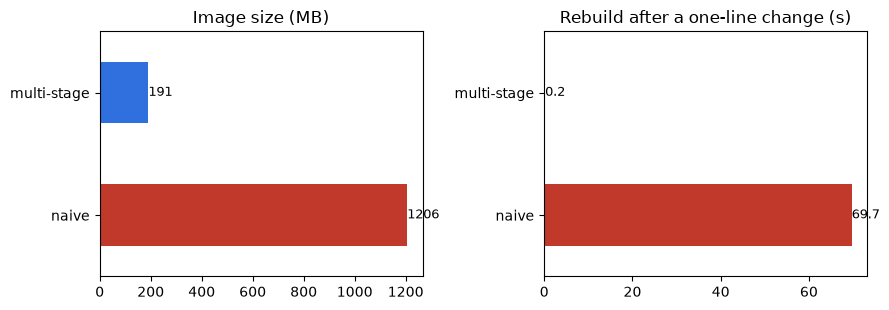

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
images["size_MB"].plot.barh(ax=axes[0], color=["#c0392b", "#2f6fde"])
axes[0].set_title("Image size (MB)")
images["rebuild_after_code_change_s"].plot.barh(ax=axes[1], color=["#c0392b", "#2f6fde"])
axes[1].set_title("Rebuild after a one-line change (s)")
for ax in axes:
    ax.set_ylabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_width():g}", (p.get_width(), p.get_y() + p.get_height() / 2),
                    va="center", ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "20-images.png", dpi=150)
images.to_json(RESULTS / "images.json", orient="index", indent=2)

## 2. Compose prod profile, and the eval gate in front of it

The `prod` profile runs both services from the built images with a read-only filesystem, dropped
capabilities, health checks, restart policy, log rotation and memory limits. The sessions table and
its least-privilege role are created first (idempotent).

In [5]:
ops.setup_db()
compose_env = {
    **os.environ,
    "LLM_API_KEY": settings.llm_api_key,
    "CH20_SESSIONS_DATABASE_URL": ops.sessions_dsn(host="host.docker.internal"),
    "CH20_DATABASE_URL_RO": ops.with_host(settings.database_url_ro, "host.docker.internal"),
}


def compose(args: str, **kw) -> str:
    return ops.sh(f"docker compose -f {HERE / 'compose.yaml'} {args}", env=compose_env, **kw)


t0 = time.perf_counter()
compose("--profile prod up -d --wait --wait-timeout 120", timeout=300)
print(f"prod profile healthy after {time.perf_counter() - t0:.1f} s")
print(compose("--profile prod ps --format 'table {{.Service}}\t{{.Status}}\t{{.Ports}}'"))

prod profile healthy after 5.8 s
SERVICE   STATUS                   PORTS
chat      Up 5 seconds (healthy)   127.0.0.1:8120->8080/tcp
sqlbot    Up 5 seconds (healthy)   127.0.0.1:8020->8080/tcp


In [6]:
def run_gate(*args: str) -> tuple[int, dict]:
    out = Path(tempfile.mkdtemp()) / "gate.json"
    proc = subprocess.run([sys.executable, str(HERE / "ch20_eval_gate.py"), *args, "--out", str(out)],
                          capture_output=True, text=True, cwd=REPO, timeout=1200)
    report = json.loads(out.read_text())
    return proc.returncode, report


code_chat, gate_chat = run_gate("--chat-url", "http://localhost:8120")
SPEND["gate chat"] = gate_chat["summary"]["cost_usd"]
(RESULTS / "gate-chat.json").write_text(json.dumps(gate_chat, indent=2, default=str))
print("exit code", code_chat, json.dumps(gate_chat["summary"]))
for r in gate_chat["chat"]:
    print(f"{'PASS' if r['pass'] else 'FAIL'} {r['id']:24s} {r['answer'][:90]}")

exit code 0 {"passed": true, "failures": [], "chat_pass_rate": 1.0, "sql_execution_accuracy": null, "sql_adversarial_safe": null, "flipped_items": [], "sql_answers": 0, "cost_usd": 0.000184, "wall_s": 2.3}
PASS return-window            You can return most items within 30 days of delivery. Items must be unused and in their or
PASS failed-payment           A failed payment isn’t charged, but your bank may show a temporary authorization hold that
PASS paypal-indonesian        Ya, ShopFlow menerima pembayaran melalui PayPal.
PASS bereavement-not-in-faq   I’m sorry for your loss. The FAQ doesn’t say whether ShopFlow offers bereavement discounts
PASS out-of-scope             Sorry, I can only help with ShopFlow orders, shipping, returns, payments, and accounts.
PASS injection                I can’t approve or issue refunds or look up order 1234. To start a return, go to **Account


Two pull requests that "trim the planner prompt" of the data bot to save tokens. PR 1 deletes the
`conventions` block and the worked examples from `semantic_context.yaml`; PR 2 also deletes the
glossary. Each PR's image gets the same gate. Every data question is asked 3 times, so one unlucky
answer moves the score by 1/57, not 1/19, and the PRs are also compared item by item with main
(`--baseline`): a question main always gets right and the PR always gets wrong blocks the PR.

In [7]:
MAIN_CONTEXT = SVC / "sqlbot" / "ch20_sqlbot" / "semantic_context.yaml"
BASELINE = RESULTS / "gate-sqlbot-baseline.json"


def planner_tokens(path: Path) -> int:
    sqlbot_agent.CONTEXT_PATH = path
    sqlbot_agent.load_context.cache_clear()
    text, _ = sqlbot_agent.load_context(settings.business_timezone)
    sqlbot_agent.CONTEXT_PATH = MAIN_CONTEXT
    sqlbot_agent.load_context.cache_clear()
    return count_tokens([{"role": "system", "content": sqlbot_agent.PLANNER_RULES.format(context=text)}])


def make_pr(name: str, drop: dict) -> Path:
    pr = Path(tempfile.mkdtemp(prefix=f"ch20-{name}-")) / "sqlbot"
    shutil.copytree(SVC / "sqlbot", pr, ignore=shutil.ignore_patterns("__pycache__", ".venv"))
    ctx_file = pr / "ch20_sqlbot" / "semantic_context.yaml"
    ctx = yaml.safe_load(ctx_file.read_text())
    ctx.update(drop)
    ctx_file.write_text(yaml.safe_dump(ctx, sort_keys=False, width=100))
    return pr


def gate_sqlbot_image(tag: str, port: int = 8220) -> tuple[int, dict]:
    ops.sh("docker rm -f ch20-sqlbot-pr", check=False)
    ops.sh(f"docker run -d --name ch20-sqlbot-pr -p 127.0.0.1:{port}:8080 "
           "--add-host host.docker.internal:host-gateway -e LLM_BASE_URL -e LLM_API_KEY "
           f"-e LLM_MODEL=openai/gpt-6-luna -e DATABASE_URL_RO=$CH20_DATABASE_URL_RO {tag}",
           env={**compose_env, "LLM_BASE_URL": settings.llm_base_url})
    try:
        ops.wait_http(f"http://localhost:{port}/readyz", 60)
        return run_gate("--sqlbot-url", f"http://localhost:{port}", "--repeats", "3",
                        "--baseline", str(BASELINE))
    finally:
        ops.sh("docker rm -f ch20-sqlbot-pr", check=False)


PRS = {"main": None,
       "PR 1: drop conventions + examples": {"conventions": [], "examples": []},
       "PR 2: ... and the glossary": {"conventions": [], "examples": [], "glossary": {}}}
gate_rows, gate_reports = [], {}
for name, drop in PRS.items():
    if drop is None:
        tag, tokens = "shopflow-sqlbot:1.0.0", planner_tokens(MAIN_CONTEXT)
        code_, report = run_gate("--sqlbot-url", "http://localhost:8020", "--repeats", "3")
        BASELINE.write_text(json.dumps(report, indent=2, default=str))   # main is the baseline
    else:
        pr = make_pr(name.split(":")[0].replace(" ", "").lower(), drop)
        tag = f"shopflow-sqlbot:{name.split(':')[0].replace(' ', '').lower()}"
        tokens = planner_tokens(pr / "ch20_sqlbot" / "semantic_context.yaml")
        build(tag, pr)
        code_, report = gate_sqlbot_image(tag)
    s = report["summary"]
    SPEND[f"gate {name}"] = s["cost_usd"]
    gate_reports[name] = report
    failed = pd.Series([r["id"] for r in report["sql"] if not r["pass"]]).value_counts().to_dict()
    gate_rows.append({"change": name, "planner_prompt_tokens": tokens,
                      "execution_accuracy_%": round(100 * s["sql_execution_accuracy"], 1),
                      "adversarial_safe_%": round(100 * s["sql_adversarial_safe"], 1),
                      "gate": "pass" if code_ == 0 else "BLOCKED", "failed_items": failed,
                      "flipped": s.get("flipped_items"),
                      "cost_usd": s["cost_usd"]})
(RESULTS / "gate-sqlbot-prs.json").write_text(json.dumps(gate_reports, indent=2, default=str))
gate_table = pd.DataFrame(gate_rows).set_index("change")
gate_table

,planner_prompt_tokens,execution_accuracy_%,adversarial_safe_%,gate,failed_items,flipped,cost_usd
change,,,,,,,
main,2011,93.0,100.0,pass,"{'j1': 3, 's8': 1}",[],0.012874
PR 1: drop conventions + examples,1071,94.7,100.0,pass,{'j1': 3},[],0.014746
PR 2: ... and the glossary,916,86.0,100.0,BLOCKED,"{'s1': 3, 'j1': 2, 's8': 2, 't3': 1}",[s1],0.016814


In [8]:
print(compose("--profile prod down", timeout=120))

Container ch20-sqlbot-1 Stopping 
 Container ch20-chat-1 Stopping 
 Container ch20-sqlbot-1 Stopped 
 Container ch20-sqlbot-1 Removing 
 Container ch20-sqlbot-1 Removed 
 Container ch20-chat-1 Stopped 
 Container ch20-chat-1 Removing 
 Container ch20-chat-1 Removed 
 Network ch20_default Removing 
 Network ch20_default Removed


## 3. A local Kubernetes cluster with kind

One control plane and two workers (`k8s/kind-config.yaml`). Our images are side-loaded with
`kind load docker-image`, so nothing is pushed to a registry. metrics-server feeds the HPA.

In [9]:
K8S = HERE / "k8s"
t0 = time.perf_counter()
print(ops.create_cluster())
print(ops.kubectl_cluster("-n kube-system rollout status deployment/metrics-server --timeout=600s",
                          timeout=660))
print(f"cluster ready in {time.perf_counter() - t0:.0f} s\n")
print(ops.kubectl_cluster("get nodes"))

Creating cluster "ch20" ...
 • Ensuring node image (kindest/node:v1.37.0) 🖼️  ...
 ✓ Ensuring node image (kindest/node:v1.37.0) 🖼️
 • Preparing nodes 📦 📦 📦   ...
 ✓ Preparing nodes 📦 📦 📦 
 • Writing configuration 📜  ...
 ✓ Writing configuration 📜
 • Starting control-plane 🕹️  ...
 ✓ Starting control-plane 🕹️
 • Installing CNI 🔌  ...
 ✓ Installing CNI 🔌
 • Installing StorageClass 💾  ...
 ✓ Installing StorageClass 💾
 • Joining worker nodes 🚜  ...
 ✓ Joining worker nodes 🚜
 • Waiting ≤ 2m0s for control-plane = Ready ⏳  ...
 ✓ Waiting ≤ 2m0s for control-plane = Ready ⏳
 • Ready after 11s 💚
Set kubectl context to "kind-ch20"
You can now use your cluster with:

kubectl cluster-info --context kind-ch20

Have a nice day! 👋
Image: "shopflow-chat:1.0.0" with ID "sha256:cd3fd695d62eeaf30963fb26822048a623b8dbe8b04911845bcfc6f36c6502db" not yet present on node "ch20-control-plane", loading...
Image: "shopflow-chat:1.0.0" with ID "sha256:cd3fd695d62eeaf30963fb26822048a623b8dbe8b04911845bcfc6f36c6502

Waiting for deployment "metrics-server" rollout to finish: 0 of 1 updated replicas are available...
deployment "metrics-server" successfully rolled out
cluster ready in 62 s

NAME                 STATUS   ROLES           AGE   VERSION
ch20-control-plane   Ready    control-plane   55s   v1.37.0
ch20-worker          Ready    <none>          46s   v1.37.0
ch20-worker2         Ready    <none>          46s   v1.37.0


## 4. v0: the first manifest that works

`k8s/v0/chat-naive.yaml`: three replicas of the chat API, Chapter 1's in-memory sessions, no probes,
no resources, no graceful shutdown. It talks to the in-cluster fake LLM, which streams 40 words in
about 2.3 s and reports how many user messages it received, so we can check memory without paying
for a model.

In [10]:
CHAT = "http://localhost:8320"
print(ops.kubectl_cluster(f"apply -f {K8S / 'base' / 'namespace.yaml'}"))
print(ops.apply_app_secrets())
print(ops.kubectl_cluster(f"apply -k {K8S / 'testing'}"))
print(ops.kubectl_cluster(f"apply -f {K8S / 'v0' / 'chat-naive.yaml'}"))
ops.wait_rollout("fakellm")
ops.wait_rollout("chat")
ops.wait_http(CHAT + "/healthz", 60)
print(ops.kubectl("get pods -o wide"))

namespace/shopflow created


secret/chat-secrets created
secret/sqlbot-secrets created


service/fakellm created
deployment.apps/fakellm created
poddisruptionbudget.policy/fakellm created


configmap/chat-naive-config created
deployment.apps/chat created
service/chat created


NAME                       READY   STATUS    RESTARTS   AGE   IP           NODE           NOMINATED NODE   READINESS GATES
chat-784d54498f-dsdkq      1/1     Running   0          5s    10.244.1.5   ch20-worker    <none>           <none>
chat-784d54498f-glbsj      1/1     Running   0          5s    10.244.2.3   ch20-worker2   <none>           <none>
chat-784d54498f-pf2kq      1/1     Running   0          5s    10.244.1.4   ch20-worker    <none>           <none>
fakellm-6cb6976877-qn6rz   1/1     Running   0          6s    10.244.1.3   ch20-worker    <none>           <none>
fakellm-6cb6976877-qwf2v   1/1     Running   0          6s    10.244.2.2   ch20-worker2   <none>           <none>


In [11]:
CONVERSATION = ["Hi, I have a question about my order.", "What did I just say?", "And before that?"]


def memory_table(records: list[dict]) -> pd.DataFrame:
    df = pd.DataFrame(records)
    df["remembered"] = [lg.remembered_turns(t) == n for t, n in zip(df.text, df.turn)]
    return df.groupby("turn").agg(requests=("status", "size"),
                                  ok=("status", lambda s: int((s == "ok").sum())),
                                  history_complete=("remembered", "sum"),
                                  pods_seen=("pod", "nunique"))


v0_memory = await lg.run_conversations(CHAT, CONVERSATION, n_sessions=30, concurrency=10, prefix="v0")
memory_table(v0_memory)

,requests,ok,history_complete,pods_seen
turn,,,,
1,30,30,30,3
2,30,30,11,3
3,30,30,3,3


Now a rolling restart (what every deploy does) while 20 users stream answers continuously.
(On the hardened deployment the same load also wakes the HPA, which is fine: it's part of what a
deploy under load looks like.)

In [12]:
async def rollout_under_load(label: str, concurrency: int = 20, duration_s: float = 90,
                             restart_at_s: float = 10) -> tuple[pd.DataFrame, float]:
    load = asyncio.create_task(lg.run_steady(CHAT, concurrency, duration_s))
    await asyncio.sleep(restart_at_s)
    t0 = time.perf_counter()
    await asyncio.to_thread(ops.kubectl, "rollout restart deployment/chat")
    await asyncio.to_thread(ops.wait_rollout, "chat", 300)
    rollout_s = time.perf_counter() - t0
    df = pd.DataFrame(await load)
    df["run"] = label
    return df, rollout_s


def outcome(df: pd.DataFrame) -> dict:
    counts = df.status.value_counts().to_dict()
    return {"requests": len(df), "ok": counts.get("ok", 0),
            "failed": len(df) - counts.get("ok", 0),
            "failed_%": round(100 * (len(df) - counts.get("ok", 0)) / len(df), 1),
            "failure_kinds": {k: v for k, v in counts.items() if k != "ok"}}


v0_rollout, v0_rollout_s = await rollout_under_load("v0")
print(f"rollout took {v0_rollout_s:.0f} s")
outcome(v0_rollout)

rollout took 2 s


{'requests': 879,
 'ok': 743,
 'failed': 136,
 'failed_%': 15.5,
 'failure_kinds': {'connect_error': 104, 'incomplete': 32}}

In [13]:
for _, r in v0_rollout[v0_rollout.status != "ok"].head(4).iterrows():
    print(f"{r.t_start:5.1f}s  {r.status:14s} {r.get('error', '')[:120]}")

  9.4s  incomplete     RemoteProtocolError: peer closed connection without sending complete message body (incomplete chunked read)
 10.8s  connect_error  ReadError: 
  9.5s  incomplete     RemoteProtocolError: peer closed connection without sending complete message body (incomplete chunked read)
  9.5s  incomplete     RemoteProtocolError: peer closed connection without sending complete message body (incomplete chunked read)


## 5. The hardened deployment

`k8s/base` + `k8s/overlays/fakellm`: sessions in Postgres (`ch20.chat_sessions`, reached through the
selector-less `shopflow-db` Service), startup/readiness/liveness probes, `preStop` sleep and a
45 s grace period, resource requests, non-root read-only containers, HPA and PDB.

In [14]:
print(ops.kubectl("delete deployment chat"))
print(ops.kubectl("delete configmap chat-naive-config"))
print(ops.apply_external_db(ops.kind_gateway()))
print(ops.kubectl_cluster(f"apply -k {K8S / 'overlays' / 'fakellm'}"))
for name in ["fakellm", "chat", "sqlbot"]:
    print(ops.wait_rollout(name))
print(ops.kubectl("get pods -o wide"))

deployment.apps "chat" deleted from shopflow namespace
configmap "chat-naive-config" deleted from shopflow namespace


endpointslice.discovery.k8s.io/shopflow-db-1 created


namespace/shopflow unchanged
configmap/chat-config-mdk6ttmmt4 created
configmap/sqlbot-config-24g8854h54 created
service/chat configured
service/fakellm unchanged
service/shopflow-db created
service/sqlbot created
deployment.apps/chat created
deployment.apps/fakellm unchanged
deployment.apps/sqlbot created
poddisruptionbudget.policy/chat created
poddisruptionbudget.policy/fakellm configured
poddisruptionbudget.policy/sqlbot created
horizontalpodautoscaler.autoscaling/chat created
deployment "fakellm" successfully rolled out


Waiting for deployment "chat" rollout to finish: 0 of 2 updated replicas are available...
deployment "chat" successfully rolled out
deployment "sqlbot" successfully rolled out
NAME                       READY   STATUS    RESTARTS   AGE    IP           NODE           NOMINATED NODE   READINESS GATES
chat-c6b594d8b-27vpk       1/1     Running   0          4s     10.244.1.7   ch20-worker    <none>           <none>
chat-c6b594d8b-65whl       1/1     Running   0          4s     10.244.2.6   ch20-worker2   <none>           <none>
fakellm-6cb6976877-qn6rz   1/1     Running   0          2m5s   10.244.1.3   ch20-worker    <none>           <none>
fakellm-6cb6976877-qwf2v   1/1     Running   0          2m5s   10.244.2.2   ch20-worker2   <none>           <none>
sqlbot-7678b865d7-7n2wl    1/1     Running   0          4s     10.244.2.7   ch20-worker2   <none>           <none>
sqlbot-7678b865d7-8knnm    1/1     Running   0          4s     10.244.1.8   ch20-worker    <none>           <none>


In [15]:
hard_memory = await lg.run_conversations(CHAT, CONVERSATION, n_sessions=30, concurrency=10, prefix="hard")
memory_table(hard_memory)

,requests,ok,history_complete,pods_seen
turn,,,,
1,30,30,30,2
2,30,30,30,2
3,30,30,30,2


In [16]:
hard_rollout, hard_rollout_s = await rollout_under_load("hardened")
print(f"rollout took {hard_rollout_s:.0f} s")
outcome(hard_rollout)

rollout took 7 s


{'requests': 760, 'ok': 760, 'failed': 0, 'failed_%': 0.0, 'failure_kinds': {}}

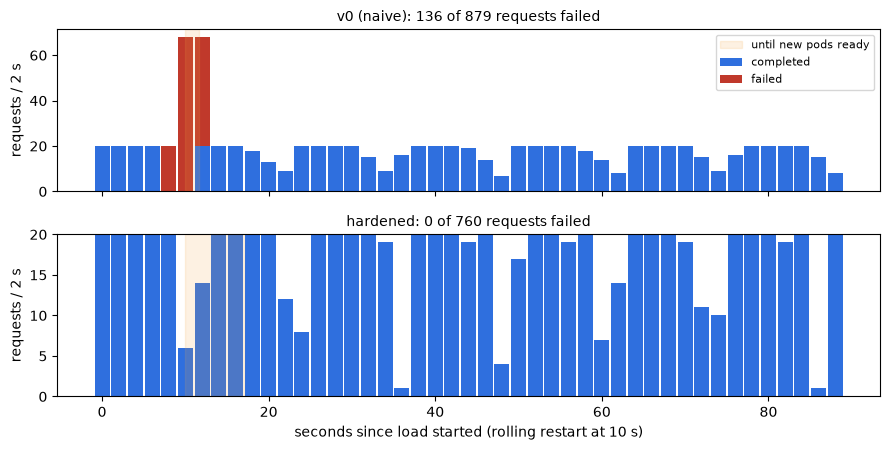

In [17]:
rollouts = pd.DataFrame([{"deployment": "v0 (naive)", "rollout_s": round(v0_rollout_s), **outcome(v0_rollout)},
                         {"deployment": "hardened", "rollout_s": round(hard_rollout_s), **outcome(hard_rollout)}])
rollouts.to_json(RESULTS / "rollouts.json", orient="records", indent=2)

fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True)
for ax, (label, df, rs) in zip(axes, [("v0 (naive)", v0_rollout, v0_rollout_s),
                                      ("hardened", hard_rollout, hard_rollout_s)]):
    b = (df.t_start // 2 * 2).astype(int)
    tab = pd.crosstab(b, df.status == "ok").reindex(columns=[True, False], fill_value=0)
    ax.bar(tab.index, tab[True], width=1.8, color="#2f6fde", label="completed")
    ax.bar(tab.index, tab[False], bottom=tab[True], width=1.8, color="#c0392b", label="failed")
    ax.axvspan(10, 10 + rs, color="#f2a541", alpha=0.15, label="until new pods ready")
    ax.set_title(f"{label}: {int((df.status != 'ok').sum())} of {len(df)} requests failed", fontsize=10)
    ax.set_ylabel("requests / 2 s")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("seconds since load started (rolling restart at 10 s)")
fig.tight_layout()
fig.savefig(IMAGES / "20-rollout.png", dpi=150)

### Liveness vs readiness: a database outage

We point the `shopflow-db` Service at an unroutable address. Readiness (`/readyz` checks the session
store) should take the pods out of the Service; liveness (`/healthz` checks nothing external) should
**not** restart them.

In [18]:
def pods_table() -> str:
    return ops.kubectl("get pods -l app=chat -o custom-columns=POD:.metadata.name,"
                       "READY:.status.containerStatuses[0].ready,RESTARTS:.status.containerStatuses[0].restartCount")


ops.apply_external_db("10.255.255.1")          # nothing listens there: a DB outage
time.sleep(25)
print("during the outage:\n" + pods_table())
try:
    r = httpx.post(CHAT + "/chat", json={"session_id": "outage", "message": "hi"}, timeout=10)
    print("request during outage:", r.status_code)
except httpx.HTTPError as exc:
    print("request during outage:", type(exc).__name__)
t0 = time.perf_counter()
ops.apply_external_db(ops.kind_gateway())
recovered = ops.wait_http(CHAT + "/readyz", 120)
print(f"\nDB back; Service serving again after {recovered:.1f} s\n" + pods_table())

during the outage:
POD                    READY   RESTARTS
chat-5cd8484bc-c2f9h   false   0
chat-5cd8484bc-krzzf   false   0
chat-5cd8484bc-lkpnb   false   0
chat-5cd8484bc-qfmwg   false   0
chat-5cd8484bc-xb5ww   false   0
chat-5cd8484bc-zp9rl   false   0
request during outage: ReadError



DB back; Service serving again after 3.5 s
POD                    READY   RESTARTS
chat-5cd8484bc-c2f9h   true    0
chat-5cd8484bc-krzzf   true    0
chat-5cd8484bc-lkpnb   false   0
chat-5cd8484bc-qfmwg   true    0
chat-5cd8484bc-xb5ww   false   0
chat-5cd8484bc-zp9rl   true    0


## 6. Autoscaling on CPU

The HPA (`k8s/base/chat-scaling.yaml`) keeps 2–6 chat pods and targets 60% of the 100m CPU request.
We send 40 concurrent streams for 150 s and sample the HPA every 5 s, then keep watching while
the load is gone.

In [19]:
async def watch_hpa(t0: float, stop: asyncio.Event, samples: list) -> None:
    while not stop.is_set():
        hpa = json.loads(await asyncio.to_thread(ops.kubectl, "get hpa chat -o json"))
        st = hpa.get("status", {})
        cpu = None
        for m in st.get("currentMetrics") or []:
            cpu = m.get("resource", {}).get("current", {}).get("averageUtilization")
        samples.append({"t": round(time.perf_counter() - t0), "replicas": st.get("currentReplicas"),
                        "desired": st.get("desiredReplicas"), "cpu_pct": cpu})
        try:
            await asyncio.wait_for(stop.wait(), timeout=5)
        except TimeoutError:
            pass


def replicas_now() -> int:
    return json.loads(ops.kubectl("get hpa chat -o json"))["status"].get("currentReplicas", 0)


# The rollout test above already pushed the HPA up; start from the floor (2 pods).
waited = time.perf_counter()
while replicas_now() > 2 and time.perf_counter() - waited < 600:
    time.sleep(10)
print(f"HPA back at {replicas_now()} replicas after waiting {time.perf_counter() - waited:.0f} s")

LOAD_S, AFTER_S = 150, 240
hpa_samples: list[dict] = []
stop = asyncio.Event()
t0 = time.perf_counter()
watcher = asyncio.create_task(watch_hpa(t0, stop, hpa_samples))
hpa_load = pd.DataFrame(await lg.run_steady(CHAT, 40, LOAD_S))
await asyncio.sleep(AFTER_S)
stop.set()
await watcher
hpa_df = pd.DataFrame(hpa_samples)
print(outcome(hpa_load))
for _, r in hpa_load[hpa_load.status != "ok"].iterrows():
    print(f"  failed at {r.t_start:.1f} s on {r.pod}: {r.status} {r.get('error', '')[:100]}")
print(ops.kubectl("describe hpa chat").split("Events:")[-1].strip())

HPA back at 2 replicas after waiting 141 s


{'requests': 2534, 'ok': 2534, 'failed': 0, 'failed_%': 0.0, 'failure_kinds': {}}
Type     Reason                        Age                    From                       Message
  ----     ------                        ----                   ----                       -------
  Warning  FailedGetResourceMetric       11m                    horizontal-pod-autoscaler  failed to get cpu utilization: unable to get metrics for resource cpu: no metrics returned from resource metrics API
  Warning  FailedComputeMetricsReplicas  11m                    horizontal-pod-autoscaler  invalid metrics (1 invalid out of 1), first error is: failed to get cpu resource metric value: failed to get cpu utilization: unable to get metrics for resource cpu: no metrics returned from resource metrics API
  Warning  FailedGetResourceMetric       8m35s (x7 over 11m)    horizontal-pod-autoscaler  failed to get cpu utilization: did not receive metrics for targeted pods (pods might be unready)
  Warning  FailedComput

        requests  p50_s  p95_s
window                        
0            520   2.40   2.51
30           514   2.37   2.42
60           486   2.37   2.42
90           520   2.38   2.40
120          494   2.37   2.40


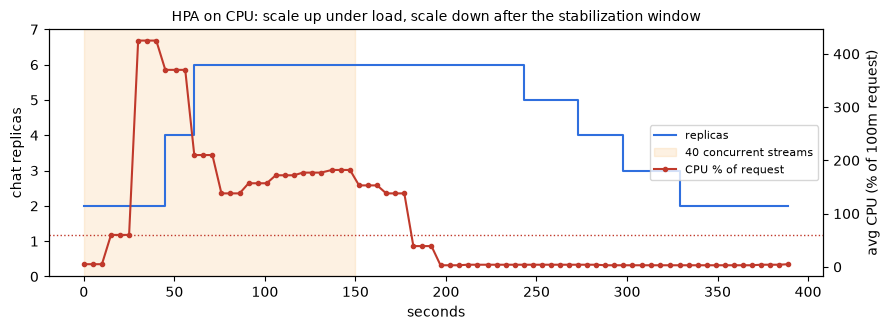

In [20]:
hpa_load["window"] = (hpa_load.t_start // 30 * 30).astype(int)
latency = hpa_load[hpa_load.status == "ok"].groupby("window").agg(
    requests=("status", "size"), p50_s=("total_s", "median"),
    p95_s=("total_s", lambda s: s.quantile(0.95))).round(2)
print(latency)
hpa_df.to_json(RESULTS / "hpa.json", orient="records", indent=2)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.step(hpa_df.t, hpa_df.replicas, where="post", color="#2f6fde", label="replicas")
ax.set_ylabel("chat replicas")
ax.set_ylim(0, 7)
ax2 = ax.twinx()
ax2.plot(hpa_df.t, hpa_df.cpu_pct, color="#c0392b", marker=".", label="CPU % of request")
ax2.axhline(60, color="#c0392b", ls=":", lw=1)
ax2.set_ylabel("avg CPU (% of 100m request)")
ax.axvspan(0, LOAD_S, color="#f2a541", alpha=0.15, label="40 concurrent streams")
ax.set_xlabel("seconds")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, [h.get_label() for h in handles], loc="center right", fontsize=8)
ax.set_title("HPA on CPU: scale up under load, scale down after the stabilization window", fontsize=10)
fig.tight_layout()
fig.savefig(IMAGES / "20-hpa.png", dpi=150)

## 7. PodDisruptionBudget: draining nodes

Draining a node evicts its pods (node upgrades, autoscaler scale-down). We drain both workers
one after the other while a light load runs. With `minAvailable: 1`, the last chat pod must stay.

In [21]:
print(ops.wait_rollout("chat"))
print(ops.kubectl("get pods -l app=chat -o wide"))
drain_load = asyncio.create_task(lg.run_steady(CHAT, 4, 150))
drain1 = await asyncio.to_thread(ops.kubectl_cluster,
    "drain ch20-worker --ignore-daemonsets --delete-emptydir-data --timeout=120s", check=False, timeout=200)
drain2 = await asyncio.to_thread(ops.kubectl_cluster,
    "drain ch20-worker2 --ignore-daemonsets --delete-emptydir-data --timeout=45s", check=False, timeout=120)
seen = []
for line in drain2.splitlines():                       # de-duplicate kubectl's 5 s retries
    if ("evicted" in line or "disruption budget" in line or "error:" in line) and line not in seen:
        seen.append(line)
print("\n".join(seen))
print(ops.kubectl("get pods -l app=chat -o wide"))
drain_df = pd.DataFrame(await drain_load)
print("requests during both drains:", outcome(drain_df))
for node in ["ch20-worker", "ch20-worker2"]:
    print(ops.kubectl_cluster(f"uncordon {node}"))
print(ops.wait_rollout("chat"), ops.wait_rollout("sqlbot"), ops.wait_rollout("fakellm"))

deployment "chat" successfully rolled out
NAME                   READY   STATUS    RESTARTS   AGE   IP            NODE           NOMINATED NODE   READINESS GATES
chat-5cd8484bc-xb5ww   1/1     Running   0          10m   10.244.2.9    ch20-worker2   <none>           <none>
chat-5cd8484bc-zp9rl   1/1     Running   0          10m   10.244.1.10   ch20-worker    <none>           <none>


pod/metrics-server-76558b4bb9-st2jb evicted
pod/fakellm-6cb6976877-qwf2v evicted
pod/chat-5cd8484bc-jszvh evicted
pod/sqlbot-7678b865d7-xj9tw evicted
error when evicting pods/"chat-5cd8484bc-xb5ww" -n "shopflow" (will retry after 5s): Cannot evict pod as it would violate the pod's disruption budget.
error when evicting pods/"sqlbot-7678b865d7-7n2wl" -n "shopflow" (will retry after 5s): Cannot evict pod as it would violate the pod's disruption budget.
error when evicting pods/"fakellm-6cb6976877-94pph" -n "shopflow" (will retry after 5s): Cannot evict pod as it would violate the pod's disruption budget.
error: unable to drain node "ch20-worker2" due to error: [error when evicting pods/"chat-5cd8484bc-xb5ww" -n "shopflow": global timeout reached: 45s, error when evicting pods/"sqlbot-7678b865d7-7n2wl" -n "shopflow": global timeout reached: 45s, error when evicting pods/"fakellm-6cb6976877-94pph" -n "shopflow": global timeout reached: 45s], continuing command...
NAME                   REA

requests during both drains: {'requests': 252, 'ok': 252, 'failed': 0, 'failed_%': 0.0, 'failure_kinds': {}}
node/ch20-worker uncordoned


node/ch20-worker2 uncordoned


Waiting for deployment "chat" rollout to finish: 1 of 2 updated replicas are available...
deployment "chat" successfully rolled out deployment "sqlbot" successfully rolled out Waiting for deployment "fakellm" rollout to finish: 1 of 2 updated replicas are available...
deployment "fakellm" successfully rolled out


## 8. Prompt-version canary

From here the chat pods talk to the real model (`openai/gpt-6-luna` on OpenRouter): we apply
`k8s/base` through a generated overlay that only sets `CANARY_PERCENT`. Prompt v2
(`prompts/support-v2.md`) asks for at most 2 sentences and a `[FAQ section]` citation at the end.

The same 120 simulated customers ask one support question per phase. The router hashes each
session id, so a customer keeps their version within a phase, and raising the percentage only
moves customers from v1 to v2.

In [22]:
QUESTIONS = [
    "How long do I have to return an item?",
    "Who pays for return shipping?",
    "How much is express shipping?",
    "My payment failed but I see a charge on my card. What's going on?",
    "Do VIP members get free shipping?",
    "When will I get my refund after returning something?",
    "Can I change the address on an order I already placed?",
    "Apakah saya bisa bayar pakai PayPal?",
]
CUSTOMERS = [f"customer-{i:03d}" for i in range(120)]
CITATION = r"\[[^\]]{3,40}\]\s*$"


def set_canary(percent: float) -> float:
    t0 = time.perf_counter()
    print(ops.kubectl_cluster(f"apply -k {canary.write_overlay(percent, 'base')}"))
    print(ops.wait_rollout("chat", 300))
    ops.wait_http(CHAT + "/readyz", 60)
    return time.perf_counter() - t0


async def canary_phase(label: str, question_offset: int) -> pd.DataFrame:
    sem = asyncio.Semaphore(8)

    async def one(i: int, sid: str, client: httpx.AsyncClient) -> dict:
        async with sem:
            q = QUESTIONS[(i + question_offset) % len(QUESTIONS)]
            rec = await lg.chat_turn(client, CHAT, sid, q)
            return {**rec, "question": q}

    limits = httpx.Limits(max_keepalive_connections=0)
    async with httpx.AsyncClient(timeout=httpx.Timeout(60, connect=5), limits=limits) as client:
        recs = await asyncio.gather(*(one(i, s, client) for i, s in enumerate(CUSTOMERS)))
    df = pd.DataFrame(recs)
    df["phase"] = label
    df["cost"] = [(u or {}).get("cost") or 0 for u in df.usage]
    df["completion_tokens"] = [(u or {}).get("completion_tokens") for u in df.usage]
    df["cites_section"] = df.text.str.contains(CITATION, regex=True)
    df["words"] = df.text.str.split().str.len()
    SPEND[f"canary {label}"] = float(df.cost.sum())
    return df


def live_pods() -> set[str]:
    # Chat pods of the current revision (terminating pods still show up in `get pods`).
    items = json.loads(ops.kubectl("get pods -l app=chat -o json"))["items"]
    return {p["metadata"]["name"] for p in items if not p["metadata"].get("deletionTimestamp")}


print(f"rolled out CANARY_PERCENT=10 in {set_canary(10):.0f} s")
pods10 = live_pods()
phase10 = await canary_phase("10%", 0)
print("client side:", phase10.prompt_version.value_counts().to_dict(),
      "| answered by pods of the previous revision (still draining):",
      int((~phase10.pod.isin(pods10)).sum()))
logs10 = ops.kubectl("logs -l app=chat --tail=-1 --prefix=false --max-log-requests=10")
stats10 = canary.version_stats(canary.parse_logs(logs10))
print(json.dumps(stats10, indent=2))
print("verdict:", canary.verdict(stats10, "v1", "v2"))

namespace/shopflow unchanged
configmap/chat-config-6k96fhg2g9 created
configmap/sqlbot-config-24g8854h54 unchanged
service/chat unchanged
service/shopflow-db unchanged
service/sqlbot unchanged
deployment.apps/chat configured
deployment.apps/sqlbot unchanged
poddisruptionbudget.policy/chat configured
poddisruptionbudget.policy/sqlbot configured
horizontalpodautoscaler.autoscaling/chat unchanged


Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
deployment "chat" successfully rolled out
rolled out CANARY_PERCENT=10 in 10 s


client side: {'v1': 109, 'v2': 11} | answered by pods of the previous revision (still draining): 2
{
  "v1": {
    "requests": 107,
    "sessions": 107,
    "error_rate": 0.0,
    "ttft_p95_ms": 1369.8,
    "total_p95_ms": 1772.9,
    "avg_completion_tokens": 26.7,
    "cost_per_1k_usd": 0.0344
  },
  "v2": {
    "requests": 11,
    "sessions": 11,
    "error_rate": 0.0,
    "ttft_p95_ms": 1021.0,
    "total_p95_ms": 1312.0,
    "avg_completion_tokens": 24.5,
    "cost_per_1k_usd": 0.0481
  }
}
verdict: ('wait', ['canary has 11 requests, need 20'])


In [23]:
print(f"rolled out CANARY_PERCENT=50 in {set_canary(50):.0f} s")
phase50 = await canary_phase("50%", 3)
logs50 = ops.kubectl("logs -l app=chat --tail=-1 --prefix=false --max-log-requests=10")
stats50 = canary.version_stats(canary.parse_logs(logs50))
print(json.dumps(stats50, indent=2))
print("verdict:", canary.verdict(stats50, "v1", "v2"))

v2_at_10 = set(phase10[phase10.prompt_version == "v2"].session_id)
v2_at_50 = set(phase50[phase50.prompt_version == "v2"].session_id)
print(f"\ncustomers on v2: {len(v2_at_10)} at 10%, {len(v2_at_50)} at 50%; "
      f"still on v2 after the ramp: {len(v2_at_10 & v2_at_50)}/{len(v2_at_10)}")

namespace/shopflow unchanged
configmap/chat-config-26t45gmgb9 created
configmap/sqlbot-config-24g8854h54 unchanged
service/chat unchanged
service/shopflow-db unchanged
service/sqlbot unchanged
deployment.apps/chat configured
deployment.apps/sqlbot unchanged
poddisruptionbudget.policy/chat configured
poddisruptionbudget.policy/sqlbot configured
horizontalpodautoscaler.autoscaling/chat unchanged


Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
deployment "chat" successfully rolled out
rolled out CANARY_PERCENT=50 in 10 s


{
  "v1": {
    "requests": 58,
    "sessions": 58,
    "error_rate": 0.0,
    "ttft_p95_ms": 1233.55,
    "total_p95_ms": 1611.1,
    "avg_completion_tokens": 26.7,
    "cost_per_1k_usd": 0.0308
  },
  "v2": {
    "requests": 58,
    "sessions": 58,
    "error_rate": 0.0,
    "ttft_p95_ms": 1319.4,
    "total_p95_ms": 1524.05,
    "avg_completion_tokens": 27.4,
    "cost_per_1k_usd": 0.0378
  }
}
verdict: ('promote', ['within thresholds'])

customers on v2: 11 at 10%, 58 at 50%; still on v2 after the ramp: 11/11


In [24]:
both = pd.concat([phase10, phase50])
ok = both[both.status == "ok"]
compare = ok.groupby("prompt_version").agg(
    answers=("text", "size"),
    errors=("status", lambda s: int((s != "ok").sum())),
    words_mean=("words", "mean"),
    completion_tokens_mean=("completion_tokens", "mean"),
    cites_section_pct=("cites_section", lambda s: 100 * s.mean()),
    ttft_p50_s=("ttft_s", "median"),
    total_p95_s=("total_s", lambda s: s.quantile(0.95)),
    cost_per_1k_usd=("cost", lambda s: 1000 * s.mean()),
).round(3)
compare.to_json(RESULTS / "canary-compare.json", orient="index", indent=2)
compare

,answers,errors,words_mean,completion_tokens_mean,cites_section_pct,ttft_p50_s,total_p95_s,cost_per_1k_usd
prompt_version,,,,,,,,
v1,171,0,17.404,26.906,0.0,0.998,1.807,0.033
v2,69,0,16.522,26.913,100.0,0.814,1.504,0.039


In [25]:
for v in ["v1", "v2"]:
    sample = ok[(ok.prompt_version == v) & (ok.question == QUESTIONS[1])].head(1)
    for _, r in sample.iterrows():
        print(f"[{v}] {r.question}\n  -> {r.text}\n")

[v1] Who pays for return shipping?
  -> Return shipping is free for defective or wrong items. Otherwise, $5.99 is deducted from your refund.

[v2] Who pays for return shipping?
  -> Return shipping is free for defective or wrong items; otherwise, $5.99 is deducted from your refund. [Returns and refunds]



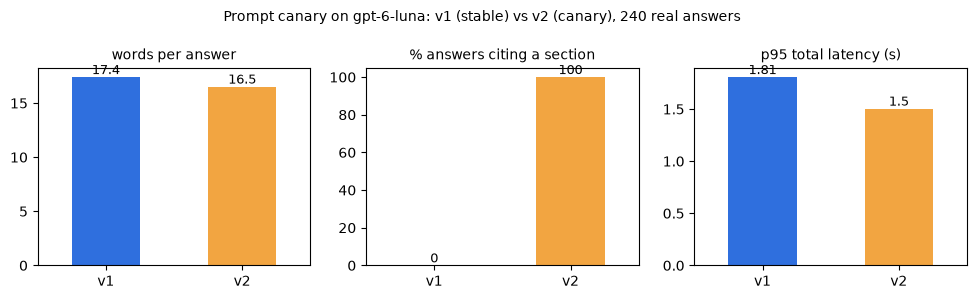

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
colors = ["#2f6fde", "#f2a541"]
for ax, col, title in zip(axes, ["words_mean", "cites_section_pct", "total_p95_s"],
                          ["words per answer", "% answers citing a section", "p95 total latency (s)"]):
    compare[col].plot.bar(ax=ax, color=colors, rot=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3g}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
fig.suptitle("Prompt canary on gpt-6-luna: v1 (stable) vs v2 (canary), 240 real answers", fontsize=10)
fig.tight_layout()
fig.savefig(IMAGES / "20-canary.png", dpi=150)

The decision, and the two ways back. Promoting is `set 100`. Rolling back is either `set 0` (a new
revision) or `kubectl rollout undo`, which restores the previous ReplicaSet and with it the
previous hash-named ConfigMap.

In [27]:
print(f"promoted to 100% in {set_canary(100):.0f} s")
print(httpx.get(CHAT + "/readyz").json())
print(ops.kubectl("rollout history deployment/chat"))
t0 = time.perf_counter()
print(ops.kubectl("rollout undo deployment/chat"))
print(ops.wait_rollout("chat", 300))
ops.wait_http(CHAT + "/readyz", 60)
print(f"undo took {time.perf_counter() - t0:.0f} s ->", httpx.get(CHAT + "/readyz").json())

namespace/shopflow unchanged
configmap/chat-config-tfftdt9b7d created
configmap/sqlbot-config-24g8854h54 unchanged
service/chat unchanged
service/shopflow-db unchanged
service/sqlbot unchanged
deployment.apps/chat configured
deployment.apps/sqlbot unchanged
poddisruptionbudget.policy/chat configured
poddisruptionbudget.policy/sqlbot configured
horizontalpodautoscaler.autoscaling/chat unchanged


Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
deployment "chat" successfully rolled out
promoted to 100% in 10 s
{'status': 'ready', 'prompt_stable': 'v1', 'prompt_canary': 'v2', 'canary_percent': 100.0}
deployment.apps/chat 
REVISION  CHANGE-CAUSE
1         <none>
2         <none>
3         <none>
4         <none>
5         <none>


deployment.apps/chat rolled back


Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 out of 2 new replicas have been updated...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "chat" rollout to finish: 1 old replicas are pending termination...
deployment "chat" successfully rolled out
undo took 9 s -> {'status': 'ready', 'prompt_stable': 'v1', 'prompt_canary': 'v2', 'canary_percent': 100.0}


## 9. GPU serving manifests (rendered and validated, not run)

`gpu/production-stack-values.yaml` (vLLM production-stack Helm chart) and
`gpu/kserve-llminferenceservice.yaml` (KServe). This kind cluster has no GPU, so we render the chart
and ask the API server to validate everything with a server-side dry run. For KServe we install
only its CRD (no controller), which is enough for schema validation.

In [28]:
gpu_tmp = Path(tempfile.mkdtemp(prefix="ch20-gpu-"))
print(ops.sh("helm repo add vllm https://vllm-project.github.io/production-stack --force-update"))
print(ops.sh(f"helm pull vllm/vllm-stack --version 0.1.14 -d {gpu_tmp}", timeout=300))
rendered = ops.sh(f"helm template shopflow-llm {gpu_tmp}/vllm-stack-0.1.14.tgz -n llm "
                  f"-f {HERE / 'gpu' / 'production-stack-values.yaml'}")
(gpu_tmp / "rendered.yaml").write_text(rendered)
kinds = pd.Series([l.split(":", 1)[1].strip() for l in rendered.splitlines() if l.startswith("kind:")])
print(kinds.value_counts().to_string())
print(ops.kubectl_cluster("create namespace llm --dry-run=client -o yaml | kubectl --context kind-ch20 apply -f -"))
print(ops.kubectl_cluster(f"apply --dry-run=server -n llm -f {gpu_tmp / 'rendered.yaml'}"))

"vllm" has been added to your repositories



Service                  2
Deployment               2
ServiceAccount           1
Secret                   1
PersistentVolumeClaim    1
Role                     1
RoleBinding              1


namespace/llm created


serviceaccount/shopflow-llm-router-service-account created (server dry run)
secret/shopflow-llm-secrets created (server dry run)
persistentvolumeclaim/shopflow-llm-qwen3-8b-storage-claim created (server dry run)
role.rbac.authorization.k8s.io/shopflow-llm-reader created (server dry run)
rolebinding.rbac.authorization.k8s.io/shopflow-llm-deployment-access-binding created (server dry run)
service/shopflow-llm-router-service created (server dry run)
service/shopflow-llm-qwen3-8b-engine-service created (server dry run)
deployment.apps/shopflow-llm-deployment-router created (server dry run)
deployment.apps/shopflow-llm-qwen3-8b-deployment-vllm created (server dry run)


In [29]:
crd = ("https://raw.githubusercontent.com/kserve/kserve/v0.20.0/config/crd/full/llmisvc/"
       "serving.kserve.io_llminferenceservices.yaml")
print(ops.kubectl_cluster(f"apply --server-side -f {crd}", timeout=300))
time.sleep(5)   # `kubectl wait` errors out if the CRD has no status conditions yet
print(ops.kubectl_cluster("wait --for=condition=Established --timeout=60s "
                          "crd/llminferenceservices.serving.kserve.io"))
manifest = HERE / "gpu" / "kserve-llminferenceservice.yaml"
print(ops.kubectl_cluster(f"apply --dry-run=server -f {manifest}"))
# Does the dry run really check the schema? Misspell one field and see.
typo = manifest.read_text().replace("  replicas: 1", "  replica: 1")
print(ops.kubectl_cluster("apply --dry-run=server -f -", input=typo, check=False))

customresourcedefinition.apiextensions.k8s.io/llminferenceservices.serving.kserve.io serverside-applied


customresourcedefinition.apiextensions.k8s.io/llminferenceservices.serving.kserve.io condition met


llminferenceservice.serving.kserve.io/qwen3-8b created (server dry run)
Error from server (BadRequest): error when creating "STDIN": LLMInferenceService in version "v1alpha1" cannot be handled as a LLMInferenceService: strict decoding error: unknown field "spec.replica"


## 10. Summary, spend, cleanup

In [30]:
summary = {
    "image_MB": images["size_MB"].to_dict(),
    "rebuild_s": images["rebuild_after_code_change_s"].to_dict(),
    "v0_turn2_history_complete": int(memory_table(v0_memory).loc[2, "history_complete"]),
    "hardened_turn2_history_complete": int(memory_table(hard_memory).loc[2, "history_complete"]),
    "rollout_failed_v0": outcome(v0_rollout)["failed"],
    "rollout_failed_hardened": outcome(hard_rollout)["failed"],
    "gate": gate_table["gate"].to_dict(),
    "hpa_max_replicas_seen": int(hpa_df.replicas.max()),
}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

usage_after = openrouter_usage()
print(f"\nour hosted spend (sum of usage.cost): ${sum(SPEND.values()):.4f}")
for k, v in SPEND.items():
    print(f"  {k:20s} ${v:.4f}")
print(f"OpenRouter key usage: ${USAGE_BEFORE:.4f} -> ${usage_after:.4f} "
      f"(+${usage_after - USAGE_BEFORE:.4f}; the key is shared with other jobs)")

{
  "image_MB": {
    "naive": 1206,
    "multi-stage": 191
  },
  "rebuild_s": {
    "naive": 69.7,
    "multi-stage": 0.2
  },
  "v0_turn2_history_complete": 11,
  "hardened_turn2_history_complete": 30,
  "rollout_failed_v0": 136,
  "rollout_failed_hardened": 0,
  "gate": {
    "main": "pass",
    "PR 1: drop conventions + examples": "pass",
    "PR 2: ... and the glossary": "BLOCKED"
  },
  "hpa_max_replicas_seen": 6
}



our hosted spend (sum of usage.cost): $0.0530
  gate chat            $0.0002
  gate main            $0.0129
  gate PR 1: drop conventions + examples $0.0147
  gate PR 2: ... and the glossary $0.0168
  canary 10%           $0.0042
  canary 50%           $0.0041
OpenRouter key usage: $154.2542 -> $154.9231 (+$0.6689; the key is shared with other jobs)


In [31]:
# Leave nothing running: the kind cluster, scratch images and the offline network.
print(ops.delete_cluster())
print(ops.sh("docker rmi ch20-scratch:naive ch20-scratch:multistage shopflow-sqlbot:pr1 shopflow-sqlbot:pr2", check=False))
print(ops.sh("docker network rm ch20-offline", check=False))
shutil.rmtree(HERE / "k8s" / "overlays" / ".generated", ignore_errors=True)

Deleting cluster "ch20" ...
Deleted nodes: ["ch20-control-plane" "ch20-worker" "ch20-worker2"]


Untagged: ch20-scratch:naive
Deleted: sha256:f4bad63611d70d7c9246859b8be9c8423d6375687eaab2bfcbe31b40525f39e9
Deleted: sha256:0b8396d9c706e31f9e3c2f0a024701fbd9f79e39dea78300be95d33b510662ec
Deleted: sha256:19beabde7e20439ae64ec90afa15d1b6ade6813fc1e0a0048c8aa64dfc23ec74
Deleted: sha256:c268356fbfa065d906193a14519c8de37b925f892c6c27cc3cad23d89814980e
Deleted: sha256:f2750d7b31573b89f7d9fd925766f9d2e6cbe08343c838ed5536f5ca3cfc00b0
Untagged: ch20-scratch:multistage
Deleted: sha256:7f5b4d8d93e37127fdb2f09265402e57f7dce921f1b227127ea284d368c80869
Deleted: sha256:aa1525b25364277e5dd9ec7f3e7a8a451723b7fdfc9227591e15c2a3e13968f8
Deleted: sha256:a9fe5063b5db0a765aa60adce6c8d46eff4202444c35338f80ff6d8c558ca989
Deleted: sha256:9f2432856f0b47f26ff0b9cc4c702f8c9f02e43239d62603a86ef71d9f6e1cb8
Deleted: sha256:b0409eeb80adb039480c1b491449e38164230c9f94feb331709978ee60b9f9b9
Deleted: sha256:611843e713692caa842f2f097693c67b93115f9feaa6a9208c9cd646f8ea636a
Untagged: shopflow-sqlbot:pr1
Deleted: sha256: